# CNN Multi-class Classification

We can follow the same steps we followed in the previous sections:

- Load the Data.
- Preprocess the data.
- Create a model.
- Fit the model.
- Evaluate.
- Try to improve the model by fine tuning different parts of it.


So, first loading the data.

Just like before I've already made a split of the `food 101` dataset and randomly selected 10 classes. You can run the following code to download the whole zip and decompress it.

In [1]:
# !wget "https://github.com/RishatTalukder/Deep_Learning_With_Tensorflow/raw/refs/heads/main/4_Convolutional_Neural_network/resource/10FoodClasses.zip"

# import zipfile

# zip_ref = zipfile.ZipFile('10FoodClasses.zip')
# zip_ref.extractall(path='resource')
# zip_ref.close()

Now Let's take a look at the `10FoodClasses` folder like before

In [2]:
import os

for dirpath, dirnames, filenames in os.walk('resource/10FoodClasses'):
    print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

There are 2 directories and 0 images in 'resource/10FoodClasses'.
There are 10 directories and 0 images in 'resource/10FoodClasses/train'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/chicken_wings'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/tiramisu'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/hamburger'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/mussels'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/cannoli'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/chocolate_cake'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/bread_pudding'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/ramen'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/miso_soup'.
There are 0 directories and 250 images in 'resource/10FoodClasses/train/creme_brulee'.
There are 10 d

Alright! 800 images in each food class in the training set and 200 images in each food class in the validation set. 

You might ask where is the testing set.

It's the same thing, to be honest. Validation set is used to see performance on the unseen data while training the model and testing set is used to see performance on the unseen data after the model is trained.

Both are unseen datasets. So, We can use it interchangeably.

I'll be using `val` set for both validation and testing.

So, let's load the data.

In [3]:
from keras.utils import image_dataset_from_directory    

training_set = image_dataset_from_directory(
    directory='resource/10FoodClasses/train',
    batch_size=24,
    image_size=(224, 224),
    shuffle=True,
    seed=42
)

validation_set = image_dataset_from_directory(
    directory='resource/10FoodClasses/val',
    batch_size=24,
    image_size=(224, 224),
    shuffle=False,
)

2026-10-25 15:59:50.773290: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Found 2500 files belonging to 10 classes.


I0000 00:00:1792922392.422969  214433 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9493 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:05:00.0, compute capability: 8.6


Found 500 files belonging to 10 classes.


Wow, now we have 10000 images,(I just hope my pc stays alive). 

So, let's do this.

What classes do we have?

In [4]:
training_set.class_names

['bread_pudding',
 'cannoli',
 'chicken_wings',
 'chocolate_cake',
 'creme_brulee',
 'hamburger',
 'miso_soup',
 'mussels',
 'ramen',
 'tiramisu']

So, nice diverse classes.

So, let's make a model. This time we have to keep in my our model have to predict `10 classes` instead of just 2. So, the model outpput layer will be a little different.

If you don't know about multi-class classification, you can read one of the previous [article on multi-class classification](https://github.com/RishatTalukder/Deep_Learning_With_Tensorflow/blob/main/pdfs/5_Multi_Class_Classification.pdf)

Mainly there onely one thing we have to do.

- The number of neurons in the output layer must be equal to the number of classes.

and the activation function for the output layer will be `softmax` instead of `sigmoid`.

So, let's make a model.

In [5]:
from keras import layers, activations, models


model4 = models.Sequential([
    layers.Input((224,224,3)),    

    layers.Rescaling(1./255),

    layers.Conv2D(10, (3,3), activation='relu'),
    layers.Conv2D(10, (3,3), activation='relu'),
    layers.AveragePooling2D((2,2)),
    
    layers.Conv2D(10, (3,3), activation='relu'),
    layers.Conv2D(10, (3,3), activation='relu'),
    layers.AveragePooling2D((4,4)),
    
    layers.Flatten(),
    
    layers.Dense(5, activation='relu'),
    layers.Dense(10, activation=activations.softmax)
])

model4.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 10)   │           280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 220, 220, 10)   │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 110, 110, 10)   │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 108, 108, 10)   │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 106, 106, 10)   │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 26, 26, 10)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6760)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │        33,805 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │            60 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,875 (144.04 KB)

 Trainable params: 36,875 (144.04 KB)

 Non-trainable params: 0 (0.00 B)

Model 4 is basically `model 3` with the output layer changed to fit our requirement.

As this model was performing pretty good on cheesecake and pizza dataset. Let's how good it handles 10 food classes.

So, let's compile and fit the model.

In [6]:
from keras import optimizers, losses, metrics

model4.compile(
    optimizer=optimizers.Adam(),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=[metrics.SparseCategoricalAccuracy()]
)

Now, I'll use 50% the validation set as validation data whole the model is training we can do that by setting `validation_split` to 0.5.

> 

In [7]:
model4.fit(
    training_set,
    epochs=10,
    validation_data=validation_set,
)

Epoch 1/10


/home/itvaya/miniforge3/envs/ml_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-10-25 15:59:54.461992: I external/local_xla/xla/service/service.cc:163] XLA service 0x79466000dad0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-25 15:59:54.462010: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 3060, Compute Capability 8.6
2026-10-25 15:59:54.700813: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-25 15:59:55.119674: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 90300

 12/105 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 2.3003 - sparse_categorical_accuracy: 0.0660

I0000 00:00:1792922400.093280  214506 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


105/105 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 2.2715 - sparse_categorical_accuracy: 0.1016

2026-10-25 16:00:05.630571: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_126', 172 bytes spill stores, 172 bytes spill loads

2026-10-25 16:00:05.683334: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_126', 192 bytes spill stores, 192 bytes spill loads



105/105 ━━━━━━━━━━━━━━━━━━━━ 13s 62ms/step - loss: 2.2715 - sparse_categorical_accuracy: 0.1016 - val_loss: 2.2809 - val_sparse_categorical_accuracy: 0.1160
Epoch 2/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 2.2360 - sparse_categorical_accuracy: 0.1424 - val_loss: 2.2427 - val_sparse_categorical_accuracy: 0.1640
Epoch 3/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 2.2007 - sparse_categorical_accuracy: 0.1784 - val_loss: 2.2338 - val_sparse_categorical_accuracy: 0.1660
Epoch 4/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 2.1430 - sparse_categorical_accuracy: 0.2064 - val_loss: 2.1769 - val_sparse_categorical_accuracy: 0.2020
Epoch 5/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 2.0741 - sparse_categorical_accuracy: 0.2260 - val_loss: 2.1811 - val_sparse_categorical_accuracy: 0.1820
Epoch 6/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 2.0178 - sparse_categorical_accuracy: 0.2352 - val_loss: 2.1043 - val_sparse_categorical_accuracy: 0.2120
Epoch 7/

<Axes: >

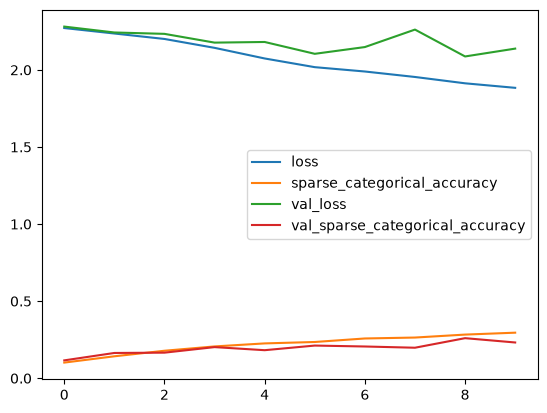

In [8]:
import pandas as pd

pd.DataFrame(
    model4.history.history
).plot()

Umph! That is not good. The model is learning because the loos is decreasing in the training set but in the validation set it is increasing and decreasing at the same it.

This is one of the best examples of `overfitting`. The model is learning the patterns of the training set but on unseen data it is performing really really bad.

So, we must fix this as fast as can. So, what can we do to reduce overfitting?

- **Increase the size of the training set**: More data more patterns.
- **Make the model a little less complex**: Yes this is a cause of overfitting. Right now the model has 9 layers and 6 of those a convolution layers. Maybe the model is learning some patterns from the training set that are not there in the validation set. 
- **Data Augmentation**: We can change the models input by changing the angle, brightness, contrast, etc. This way the model will not learn repeated patterns and generalize even bettern like I've shown in the previous section of this article.

Now, I dont have another dataset lying around with more data, so the other two options are my only way.

## Training a Simpler Model

I remove some layers from the model and let's see if it performs better.

In [33]:

model5 = models.Sequential([
    layers.Input((224,224,3)),    

    layers.Rescaling(1./255),

    layers.Conv2D(10, (3,3), activation='relu'),
    layers.AveragePooling2D((2,2)),
    
    layers.Conv2D(10, (3,3), activation='relu'),
    layers.AveragePooling2D((4,4)),
    
    layers.Flatten(),
    
    # layers.Dense(5, activation='relu'),
    layers.Dense(10, activation=activations.softmax)
])

model5.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_9 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 222, 222, 10)   │           280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_6             │ (None, 111, 111, 10)   │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 109, 109, 10)   │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_7             │ (None, 27, 27, 10)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 7290)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │        72,910 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,100 (289.45 KB)

 Trainable params: 74,100 (289.45 KB)

 Non-trainable params: 0 (0.00 B)

Now, I made a much simpler model with less layers and I even removed the `Dense` before the output layer. 

Let's see if it performs better.

In [34]:
model5.compile(
    optimizer=optimizers.Adam(),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=[metrics.SparseCategoricalAccuracy()]
)

model5.fit(
    training_set,
    epochs=10,
    validation_data=validation_set,
)

Epoch 1/10


/home/itvaya/miniforge3/envs/ml_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


105/105 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - loss: 2.1806 - sparse_categorical_accuracy: 0.1952 - val_loss: 2.0144 - val_sparse_categorical_accuracy: 0.2780
Epoch 2/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1.8814 - sparse_categorical_accuracy: 0.3280 - val_loss: 1.8980 - val_sparse_categorical_accuracy: 0.3220
Epoch 3/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1.6850 - sparse_categorical_accuracy: 0.4296 - val_loss: 1.7937 - val_sparse_categorical_accuracy: 0.3420
Epoch 4/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1.5103 - sparse_categorical_accuracy: 0.4824 - val_loss: 1.8497 - val_sparse_categorical_accuracy: 0.3580
Epoch 5/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 1.3389 - sparse_categorical_accuracy: 0.5652 - val_loss: 1.8274 - val_sparse_categorical_accuracy: 0.3840
Epoch 6/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 1.1488 - sparse_categorical_accuracy: 0.6288 - val_loss: 1.8431 - val_sparse_categorical_accuracy: 0.3640
Epoch 7/10
105

Ow wow! the model is learning very fast. That was supposed to happen i guess. The model is smaller now so it should be learning faster.

Let's see if the loss on validation set is decreasing or increasing.

<Axes: >

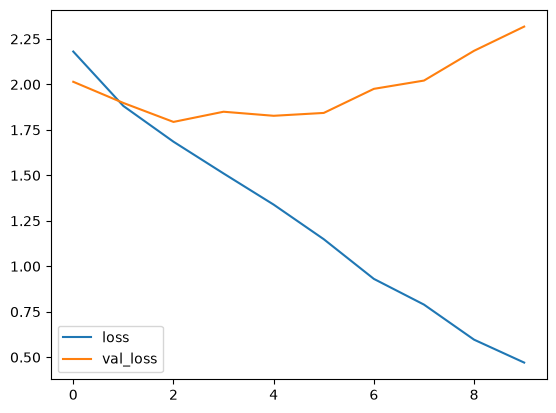

In [35]:
pd.DataFrame(
    data={
        'loss': model5.history.history['loss'],
        'val_loss': model5.history.history['val_loss'],
    }
).plot()

Nope, still heavily overfitting. The loss on training set is decreasing very fast but the loss on validation set is increasing, not good at all...

So, a less complex model is not helping us here. So, let's try with data augmentation.

In [36]:
augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(factor=0.15, fill_mode="reflect"),
    layers.RandomZoom(height_factor=0.1, width_factor=0.1),
    layers.RandomBrightness(factor=0.2)
])

This is the exact same augmentation I used in the previous section of this article.

So, in the simpler model. I'll just add this augmentation so, when the model is training it can learn more patterns from the data.

In [38]:

model6 = models.Sequential([
    layers.Input((224,224,3)),    

    augmentation,
    layers.Rescaling(1./255),

    layers.Conv2D(10, (3,3), activation='relu'),
    layers.AveragePooling2D((2,2)),
    
    layers.Conv2D(10, (3,3), activation='relu'),
    layers.AveragePooling2D((4,4)),
    
    layers.Flatten(),
    
    # layers.Dense(5, activation='relu'),
    layers.Dense(10, activation=activations.softmax)
])

model6.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_10 (Sequential)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_11 (Rescaling)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 222, 222, 10)   │           280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_10            │ (None, 111, 111, 10)   │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 109, 109, 10)   │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_11            │ (None, 27, 27, 10)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 7290)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 10)             │        72,910 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,100 (289.45 KB)

 Trainable params: 74,100 (289.45 KB)

 Non-trainable params: 0 (0.00 B)

Now, time to train.

In [39]:
model6.compile(
    optimizer=optimizers.Adam(),
    loss=losses.SparseCategoricalCrossentropy(),
    metrics=[metrics.SparseCategoricalAccuracy()]
)

model6.fit(
    training_set,
    epochs=10,
    validation_data=validation_set
)

Epoch 1/10


/home/itvaya/miniforge3/envs/ml_env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


105/105 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 2.1730 - sparse_categorical_accuracy: 0.2076 - val_loss: 2.0471 - val_sparse_categorical_accuracy: 0.2660
Epoch 2/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.9696 - sparse_categorical_accuracy: 0.2928 - val_loss: 1.8758 - val_sparse_categorical_accuracy: 0.3380
Epoch 3/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.8880 - sparse_categorical_accuracy: 0.3364 - val_loss: 1.8342 - val_sparse_categorical_accuracy: 0.3420
Epoch 4/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.8485 - sparse_categorical_accuracy: 0.3552 - val_loss: 1.7923 - val_sparse_categorical_accuracy: 0.3720
Epoch 5/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.8236 - sparse_categorical_accuracy: 0.3672 - val_loss: 1.7967 - val_sparse_categorical_accuracy: 0.3820
Epoch 6/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 1.7920 - sparse_categorical_accuracy: 0.3816 - val_loss: 1.8058 - val_sparse_categorical_accuracy: 0.3860
Epoch 7/1

Well, now the model is not learning fast like model 5 but if you take a look at the validation loss values those are not increasing either.

Let's see the loss curves.

<Axes: >

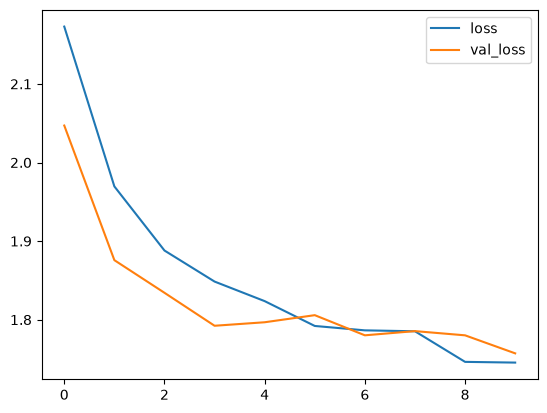

In [40]:
pd.DataFrame(
    data={
        'loss': model6.history.history['loss'],
        'val_loss': model6.history.history['val_loss'],
    }
).plot()    

Would you look at that. The validation loss is decreasing side by side with training loss. So, now we can say our model is actually learning. Hooray! clap clap clap! 

The model has learned something from the data and it is also generalizing well. So, no overfitting. That's a win!

And that's why we do data augmentation. It kinda forces a model to learn new patterns and reduce repeated patterns. this is great.

There are some other things we could've done to improve the model. I want you guys to try those things out.

- **Change learning rate**: The default learning rate is 0.001. You could try 0.01 or 0.1 or less than 0.001.

- **Change batch size**: while loading I set the batch size to 24. You could try 32 or 64.

- **Bigger or smaller image size**: I set the image size to 224x224. You could try something bigger or smaller and see how good the model performs.

So, one final thing I want to do is test the model on a custom image like I did in the binary calssification example. 